# 04 · EDA de los episodios de urgencias

Describe los episodios de la población de análisis: tamaño de los grupos, tiempo de permanencia (LOS), perfil de llegada, contactos breves y reconsultas. 

In [1]:
DATASET = 'preliminar'

In [2]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from src import config, estilo
from src.estadistica import ecdf_en_malla, tabla_los, tabla_proporciones
from src.estilo import fmt_entero, fmt_horas, fmt_pct
from src.graficos import (
    COLORES_GRUPO,
    DIAS_SEMANA,
    ETIQUETAS_CORTAS_GRUPO,
    TEXTO_PRIMARIO,
    TEXTO_SECUNDARIO,
    activar_formato_tablas,
    ancho_linea,
    aplicar_estilo,
    etiquetas_directas,
    guardar_figura,
    heatmap_hora_dia,
    leyenda_fuera,
    linea_umbral,
    marcar_umbrales,
    rotular_barras,
    titulo_hallazgo,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura
from src.tablas import mostrar_tabla, tabla_medidas

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

G1, G2, G3 = config.GRUPOS
UMBRAL = config.UMBRAL_OPERATIVO_H
SUFIJO = f'mas_{UMBRAL}h'
ERROR_KW = {'elinewidth': 1, 'ecolor': TEXTO_SECUNDARIO}
ORDEN_EDAD = list(config.GRUPOS_ETARIOS) + ['sin_dato']
OSCURO, MEDIO, CLARO = estilo.GRISES


def puntos_validos(tabla, eventos='n_eventos'):
    """Para gráficos: solo se dibujan proporciones con denominador y numerador de al menos MIN_CELDA."""
    return (tabla['n'] >= config.MIN_CELDA) & (tabla[eventos] >= config.MIN_CELDA)


def barras_con_ic(ax, x, tabla, columna_pct, columna_inf, columna_sup, valido, ancho, desplazamiento, **estilo_barras):
    """Barras de porcentaje con IC de Wilson; las celdas no válidas quedan vacías."""
    pct = tabla[columna_pct].where(valido)
    errores = np.vstack([(pct - tabla[columna_inf]).to_numpy(), (tabla[columna_sup] - pct).to_numpy()])
    barras = ax.bar(x + desplazamiento, pct, width=ancho, yerr=errores, capsize=4, error_kw=ERROR_KW, **estilo_barras)
    rotular_barras(ax, barras, pct, formato=fmt_pct, alturas=tabla[columna_sup].where(valido))
    return barras


def valor_seguro(tabla, fila, columna, conteo='n'):
    """Valor de una tabla agregada para un título, o NaN si su conteo es menor a MIN_CELDA."""
    if fila not in tabla.index or tabla.loc[fila, conteo] < config.MIN_CELDA:
        return np.nan
    return tabla.loc[fila, columna]


def titulo_figura(fig, titulo, subtitulo):
    """Título de la figura; el subtítulo indica qué dataset se usó."""
    titulo_hallazgo(fig, titulo, f'{subtitulo} · Dataset {DATASET}')

In [3]:
ARCHIVOS_DATASET = {
    'preliminar': f'episodios_preliminar_{config.UMBRAL_FUSION_MIN}min.parquet',
    'final': 'episodios_final.parquet',
}
ruta_episodios = config.DATA_INTERIM / ARCHIVOS_DATASET[DATASET]
if not ruta_episodios.exists():
    tabla_medidas({
        'dataset': DATASET,
        'archivo': f'data/interim/{ruta_episodios.name}',
        'aviso': 'El archivo no existe.',
        'qué hacer': ('Corre el notebook 03 para crear el dataset preliminar.' if DATASET == 'preliminar'
                      else 'Corre el notebook 05 para crear el dataset final.'),
    }, 'Dataset no disponible')
    raise SystemExit('Dataset no disponible: la celda se detiene.')

episodios = pd.read_parquet(ruta_episodios)
episodios['hora_llegada'] = episodios['llegada'].dt.hour
episodios['dia_semana'] = episodios['llegada'].dt.dayofweek
episodios['mes'] = episodios['llegada'].dt.to_period('M').dt.to_timestamp()
los_con_tiempo = episodios['los_h'].where(episodios['grupo'].isin(list(config.GRUPOS_TIEMPOS)))
episodios['tramo_los'] = pd.cut(
    los_con_tiempo, bins=[0, 4, 12, 24, np.inf], right=False,
    labels=['menos de 4 h', '4 a 12 h', '12 a 24 h', '24 h o más'],
)

poblacion = episodios[episodios['en_poblacion']].copy()
# Solo los episodios válidos para tiempos (columna del dataset final; el preliminar no la tiene).
if 'valido_para_tiempos' in poblacion.columns:
    para_tiempos = poblacion['valido_para_tiempos'].astype(bool)
else:
    para_tiempos = pd.Series(True, index=poblacion.index)
tiempos = poblacion[poblacion['grupo'].isin(list(config.GRUPOS_TIEMPOS)) & para_tiempos]
tabla_medidas({
    'dataset': DATASET,
    'episodios construidos': len(episodios),
    'columnas': episodios.shape[1],
    'episodios en la población de análisis': len(poblacion),
    'episodios con tiempos (grupos 2 y 3, válidos para tiempos)': len(tiempos),
}, f'Dataset de episodios: {ruta_episodios.name}')

**Dataset de episodios: episodios_preliminar_60min.parquet**

,medida,valor
0,dataset,preliminar
1,episodios construidos,468.550
2,columnas,46
3,episodios en la población de análisis,442.598
4,"episodios con tiempos (grupos 2 y 3, válidos para tiempos)",226.579


# Parte A · Univariado
## 1. Tamaño de los tres grupos

,n_episodios,pct_episodios
grupo,,
1_contacto_breve,216.019,"48,8"
2_atencion_urgencias,192.046,"43,4"
3_hospitalizado,34.533,"7,8"


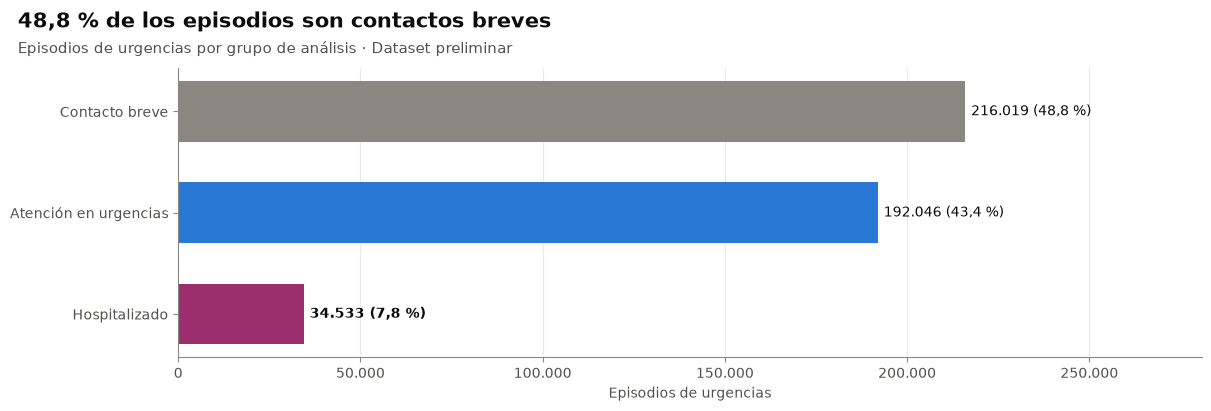

In [4]:
tamano = (
    poblacion['grupo'].value_counts()
    .reindex(list(config.GRUPOS), fill_value=0)
    .rename_axis('grupo')
    .rename('n_episodios')
    .to_frame()
)
tamano['pct_episodios'] = 100 * tamano['n_episodios'] / tamano['n_episodios'].sum()
mostrar_tabla(tabla_segura(tamano, decimales=1))
fig, ax = plt.subplots(figsize=(12, 4))
y = np.arange(len(tamano))[::-1]
ax.barh(y, tamano['n_episodios'], height=0.6, color=[COLORES_GRUPO[g] for g in tamano.index])
for yi, grupo, n, pct in zip(y, tamano.index, tamano['n_episodios'], tamano['pct_episodios']):
    texto = f'<{config.MIN_CELDA}' if n < config.MIN_CELDA else f'{fmt_entero(n)} ({fmt_pct(pct)})'
    ax.annotate(texto, xy=(n, yi), xytext=(4, 0), textcoords='offset points', va='center', color=TEXTO_PRIMARIO,
                fontweight='bold' if grupo == G3 else 'normal')
ax.set_yticks(y, [ETIQUETAS_CORTAS_GRUPO[g] for g in tamano.index])
ax.set_xlim(0, tamano['n_episodios'].max() * 1.3)
ax.grid(False)
ax.grid(axis='x')
ax.set_xlabel('Episodios de urgencias')
titulo_figura(fig, f"{fmt_pct(tamano.loc[G1, 'pct_episodios'])} de los episodios son contactos breves",
                'Episodios de urgencias por grupo de análisis')
guardar_figura(fig, f'04_tamano_grupos_{DATASET}')
plt.show()

## 2. Distribución del LOS (grupos 2 y 3)

ECDF en escala logarítmica, con líneas en 4, 12 y 24 h. La curva se evalúa en una malla fija, sin exponer observaciones individuales.

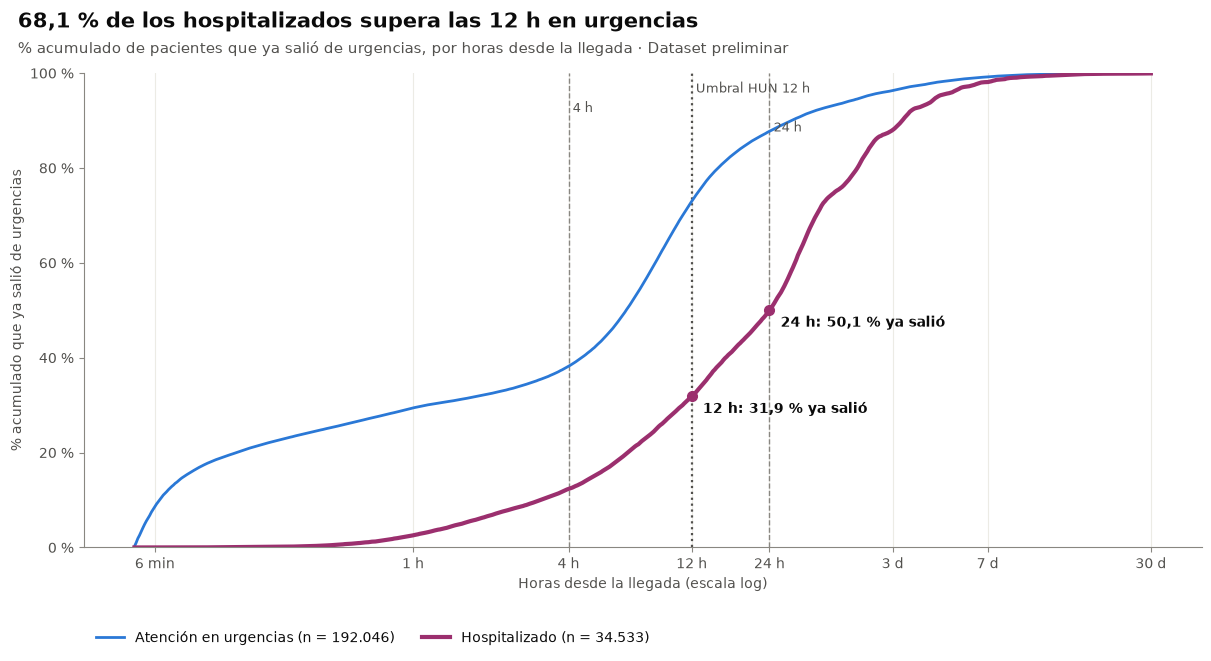

In [5]:
malla = np.logspace(np.log10(5 / 60), np.log10(24 * 30), 600)

fig, ax = plt.subplots(figsize=(12, 6.5))
for grupo in config.GRUPOS_TIEMPOS:
    los = tiempos.loc[tiempos['grupo'] == grupo, 'los_h']
    etiqueta = f'{ETIQUETAS_CORTAS_GRUPO[grupo]} (n = {fmt_entero(los.notna().sum())})'
    ax.plot(malla, ecdf_en_malla(los, malla), color=COLORES_GRUPO[grupo], linewidth=ancho_linea(grupo), label=etiqueta)

# Puntos anotados en 12 h y 24 h para el grupo 3 (proporción que ya salió de urgencias).
los_g3 = tiempos.loc[tiempos['grupo'] == G3, 'los_h'].dropna()
for horas in [12, 24]:
    salio = 100 * (los_g3 <= horas).mean()
    ax.plot(horas, salio / 100, 'o', color=COLORES_GRUPO[G3], markersize=7, zorder=4)
    ax.annotate(f'{fmt_horas(horas, 0)}: {fmt_pct(salio)} ya salió', xy=(horas, salio / 100), xytext=(8, -12),
                textcoords='offset points', color=TEXTO_PRIMARIO, fontweight='bold')
ax.set_xscale('log')
linea_umbral(ax, UMBRAL)
linea_umbral(ax, 4, "4 h", destacada=False, fila=1)
linea_umbral(ax, 24, "24 h", destacada=False, fila=2)
ax.set_xticks([0.1, 1, 4, 12, 24, 72, 168, 720], ['6 min', '1 h', '4 h', '12 h', '24 h', '3 d', '7 d', '30 d'])
ax.minorticks_off()
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _pos: fmt_pct(100 * v, 0)))
ax.grid(axis='both')
ax.set_xlabel('Horas desde la llegada (escala log)')
ax.set_ylabel('% acumulado que ya salió de urgencias')
leyenda_fuera(ax, 'debajo', ncol=2)
titulo_figura(fig, f'{fmt_pct(100 * (los_g3 > UMBRAL).mean())} de los hospitalizados supera las 12 h en urgencias',
                '% acumulado de pacientes que ya salió de urgencias, por horas desde la llegada')
guardar_figura(fig, f'04_ecdf_los_{DATASET}')
plt.show()

## 3. Perfil de los episodios: edad, sexo, hora, día y mes de llegada

grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
grupo_etario,,,
adulto,134.970,118.359,20.090
adulto_mayor,17.144,24.621,6.882
pediatria,63.905,49.066,7.561


grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
sexo,,,
femenino,116.545,111.191,19.632
masculino,99.468,80.853,14.901
otro_o_sin_dato,<10,<10,<10


grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
hora_llegada,,,
0,3.199,3.071,614
1,2.515,2.135,540
2,1.952,1.858,479
3,1.871,1.664,440
4,1.753,1.675,443
5,3.299,2.603,680
6,7.218,5.238,1.208
7,13.042,9.928,1.929
8,16.712,12.448,2.316


grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
dia_semana,,,
0,36.398,31.325,5.260
1,36.118,29.784,5.302
2,34.293,28.701,5.092
3,32.488,28.614,5.206
4,31.544,27.918,5.273
5,24.160,23.821,4.317
6,21.018,21.883,4.083


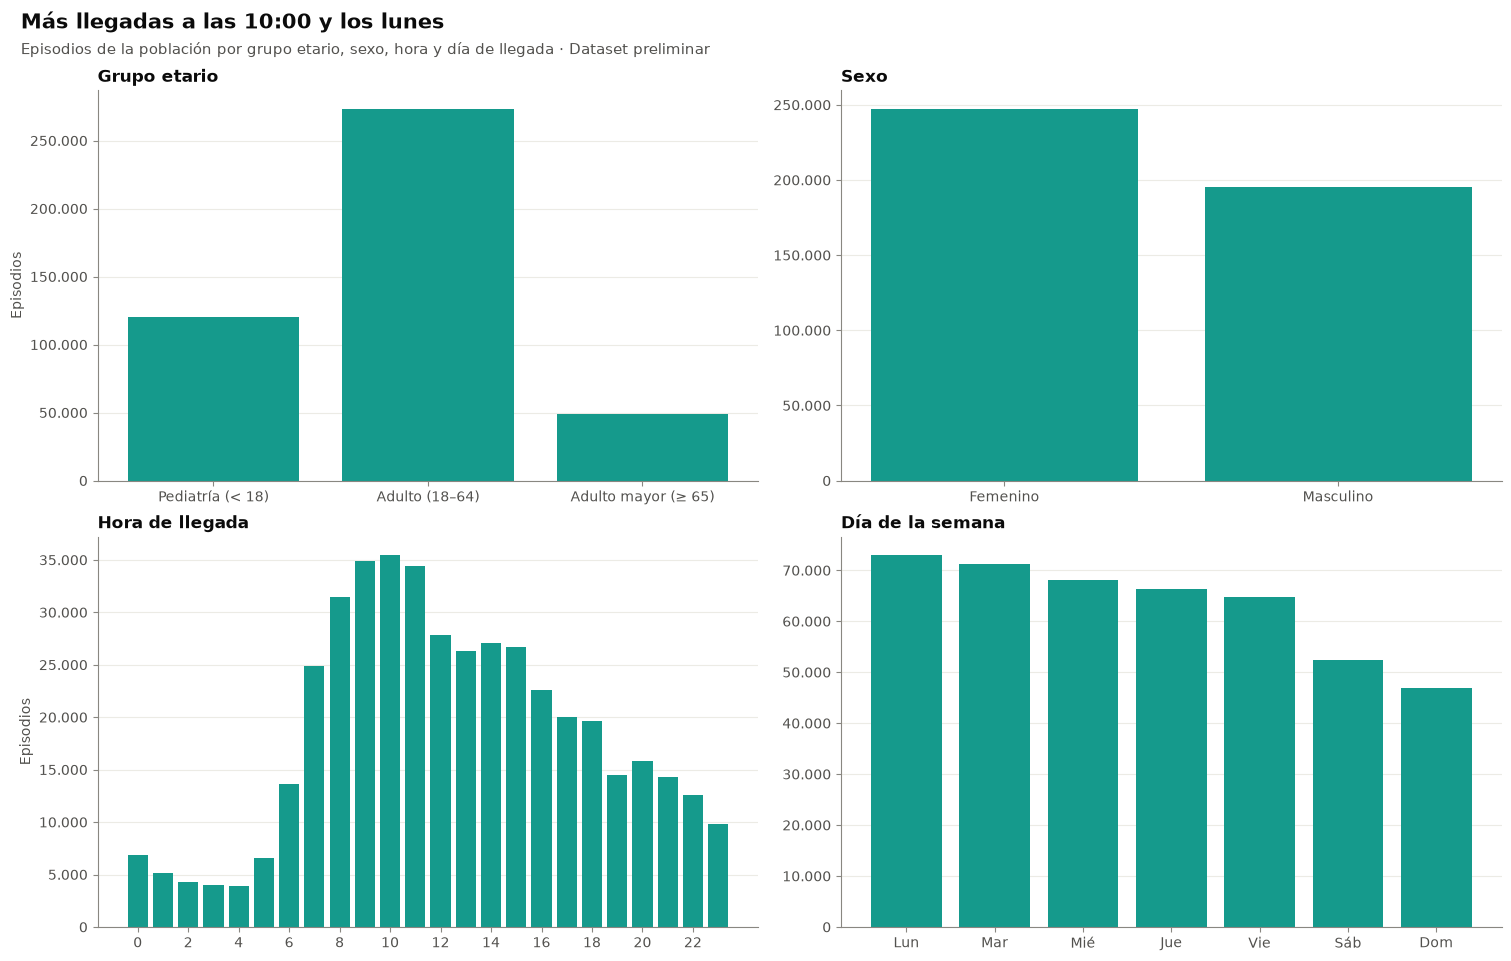

In [6]:
perfil_partes = []
for variable in ['grupo_etario', 'sexo', 'hora_llegada', 'dia_semana']:
    conteo = poblacion.groupby([variable, 'grupo']).size().unstack('grupo', fill_value=0).reindex(
        columns=list(config.GRUPOS), fill_value=0)
    mostrar_tabla(suprimir_pequenos(conteo.add_prefix('n_'), list(conteo.add_prefix('n_').columns)))
    perfil_partes.append(conteo)

fig, ejes = plt.subplots(2, 2, figsize=(15, 9.5))
conteo_edad = perfil_partes[0].reindex([e for e in ORDEN_EDAD if e in perfil_partes[0].index]).sum(axis=1)
ejes[0, 0].bar([estilo.NOMBRE_GRUPO_ETARIO[e] for e in conteo_edad.index], enmascarar_pequenos(conteo_edad, conteo_edad), color=estilo.VERDE)
ejes[0, 0].set_title('Grupo etario')
conteo_sexo = perfil_partes[1].sum(axis=1)
ejes[0, 1].bar([estilo.NOMBRE_SEXO.get(s, s) for s in conteo_sexo.index], enmascarar_pequenos(conteo_sexo, conteo_sexo), color=estilo.VERDE)
ejes[0, 1].set_title('Sexo')
conteo_hora = perfil_partes[2].sum(axis=1)
ejes[1, 0].bar(conteo_hora.index, enmascarar_pequenos(conteo_hora, conteo_hora), color=estilo.VERDE)
ejes[1, 0].set_xticks(range(0, 24, 2))
ejes[1, 0].set_title('Hora de llegada')
conteo_dia = perfil_partes[3].sum(axis=1)
ejes[1, 1].bar(conteo_dia.index, enmascarar_pequenos(conteo_dia, conteo_dia), color=estilo.VERDE)
ejes[1, 1].set_xticks(range(7), DIAS_SEMANA)
ejes[1, 1].set_title('Día de la semana')
for ax in ejes[:, 0]:
    ax.set_ylabel('Episodios')
titulo_figura(fig, f'Más llegadas a las {conteo_hora.idxmax():02d}:00 y los {estilo.DIAS_SEMANA_COMPLETOS[conteo_dia.idxmax()]}',
                'Episodios de la población por grupo etario, sexo, hora y día de llegada')
guardar_figura(fig, f'04_perfil_episodios_{DATASET}')
plt.show()

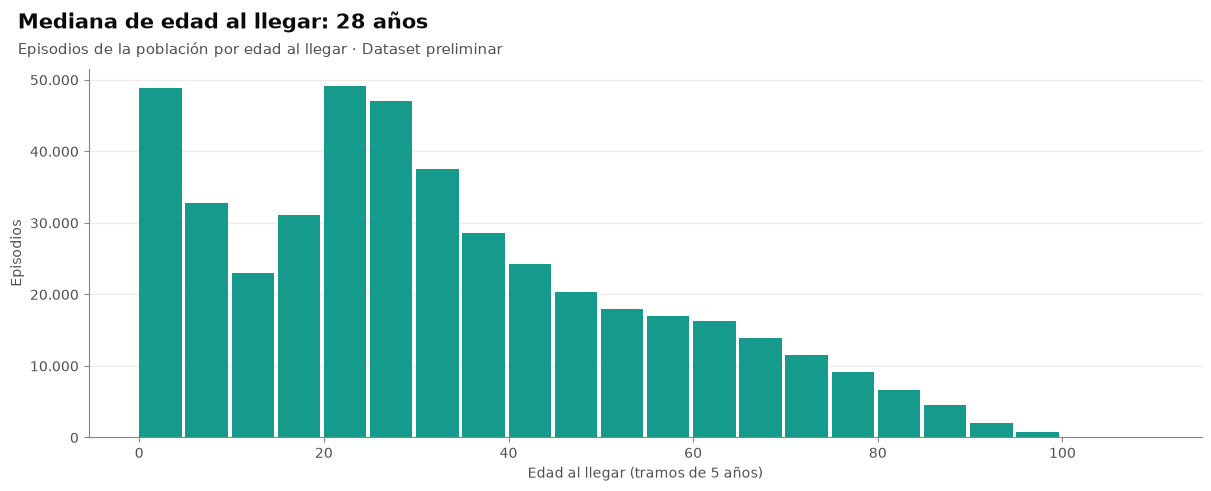

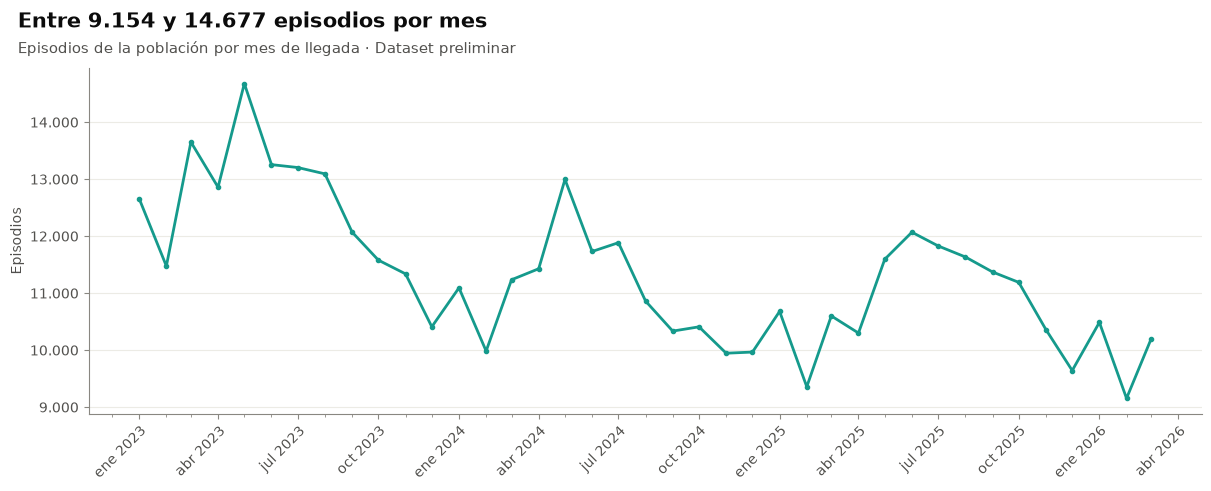

In [7]:
edad_bandas = (poblacion['edad'] // 5 * 5).dropna().astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(edad_bandas.index, enmascarar_pequenos(edad_bandas, edad_bandas), width=4.6, align='edge', color=estilo.VERDE)
ax.set_xlabel('Edad al llegar (tramos de 5 años)')
ax.set_ylabel('Episodios')
titulo_figura(fig, f"Mediana de edad al llegar: {fmt_entero(poblacion['edad'].median())} años",
                'Episodios de la población por edad al llegar')
guardar_figura(fig, f'04_edad_episodios_{DATASET}')
plt.show()

episodios_mes = poblacion.groupby('mes').size()
fig, ax = plt.subplots(figsize=(12, 4.8))
valores = enmascarar_pequenos(episodios_mes, episodios_mes)
ax.plot(valores.index, valores, marker='o', markersize=3, color=estilo.VERDE)
ax.set_ylabel('Episodios')
titulo_figura(fig, f'Entre {fmt_entero(episodios_mes.min())} y {fmt_entero(episodios_mes.max())} episodios por mes',
                'Episodios de la población por mes de llegada')
guardar_figura(fig, f'04_episodios_mes_{DATASET}')
plt.show()

## 4. Variables nuevas por grupo: `hosp_previa_30d` y `nota_consulta_urg`

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
variable          grupo                                                                            
hosp_previa_30d   1_contacto_breve      216.019     2.952         1,4            1,3            1,4
                  2_atencion_urgencias  192.046     3.049         1,6            1,5            1,6
                  3_hospitalizado        34.533       661         1,9            1,8            2,1
nota_consulta_urg 1_contacto_breve      216.019    70.794        32,8           32,6           33,0
                  2_atencion_urgencias  192.046   108.657        56,6           56,4           56,8
                  3_hospitalizado        34.533    22.133        64,1           63,6           64,6

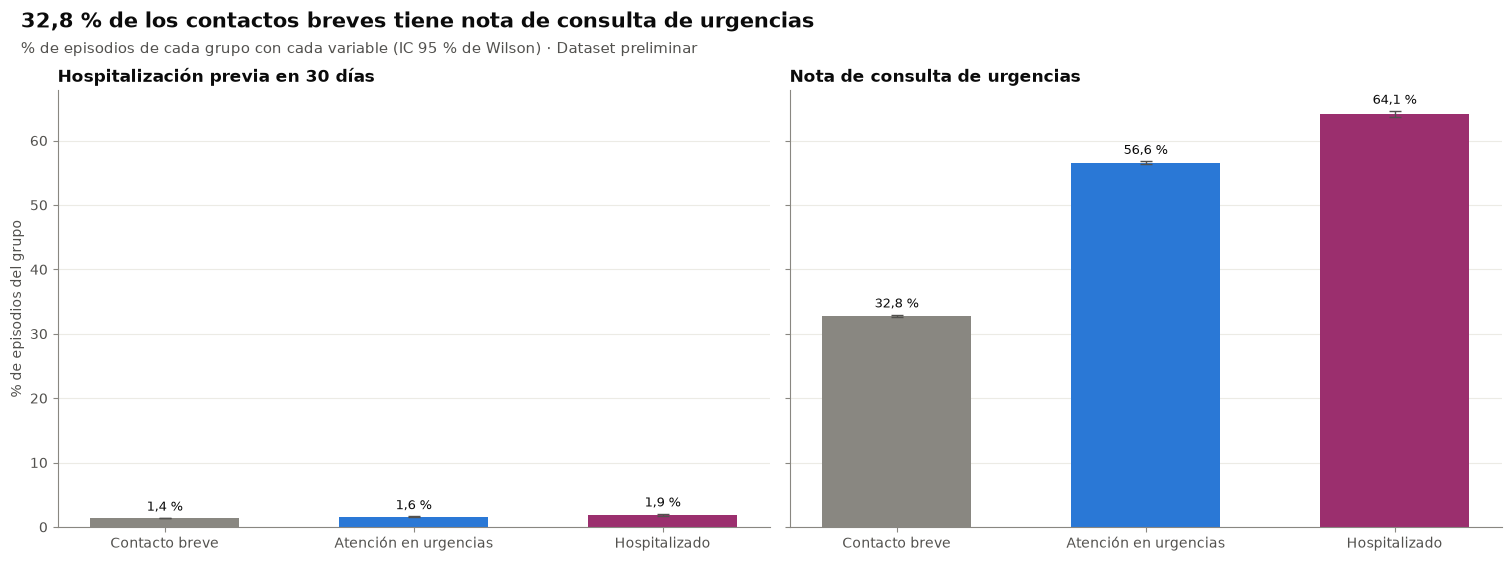

In [8]:
nuevas = []
for variable in ['hosp_previa_30d', 'nota_consulta_urg']:
    tabla = tabla_proporciones(poblacion, ['grupo'], variable)
    nuevas.append(tabla.assign(variable=variable).set_index('variable', append=True))
nuevas = pd.concat(nuevas).reorder_levels(['variable', 'grupo'])
mostrar_tabla(tabla_segura(nuevas))
grupos = list(config.GRUPOS)
x = np.arange(len(grupos))
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, (variable, titulo) in zip(ejes, [('hosp_previa_30d', 'Hospitalización previa en 30 días'),
                                          ('nota_consulta_urg', 'Nota de consulta de urgencias')]):
    tabla = nuevas.xs(variable, level='variable').reindex(grupos)
    barras_con_ic(ax, x, tabla, 'pct_eventos', 'ic_inf_eventos', 'ic_sup_eventos', puntos_validos(tabla), 0.6, 0,
                  color=[COLORES_GRUPO[g] for g in grupos])
    ax.set_xticks(x, [ETIQUETAS_CORTAS_GRUPO[g] for g in grupos])
    ax.set_title(titulo)
ejes[0].set_ylabel('% de episodios del grupo')
nota_g1 = valor_seguro(nuevas.xs('nota_consulta_urg', level='variable'), G1, 'pct_eventos', 'n_eventos')
titulo_figura(fig, f'{fmt_pct(nota_g1)} de los contactos breves tiene nota de consulta de urgencias',
                '% de episodios de cada grupo con cada variable (IC 95 % de Wilson)')
guardar_figura(fig, f'04_variables_nuevas_{DATASET}')
plt.show()

# Parte B · Bivariado
## 5. LOS por grupo

In [9]:
resumen_grupos = tabla_los(tiempos, ['grupo'])
mostrar_tabla(tabla_segura(resumen_grupos))

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_4h,pct_mas_4h,ic_inf_mas_4h,ic_sup_mas_4h,n_mas_6h,pct_mas_6h,ic_inf_mas_6h,ic_sup_mas_6h,n_mas_8h,pct_mas_8h,ic_inf_mas_8h,ic_sup_mas_8h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h,n_mas_24h,pct_mas_24h,ic_inf_mas_24h,ic_sup_mas_24h,n_mas_72h,pct_mas_72h,ic_inf_mas_72h,ic_sup_mas_72h
grupo,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2_atencion_urgencias,192.046,"6,69","0,46","12,74","29,20",118.662,"61,8","61,6","62,0",102.672,"53,5","53,2","53,7",83.141,"43,3","43,1","43,5",51.885,"27,0","26,8","27,2",23.552,"12,3","12,1","12,4",7.047,"3,7","3,6","3,8"
3_hospitalizado,34.533,"23,95","8,76","43,11","78,54",30.269,"87,7","87,3","88,0",28.407,"82,3","81,8","82,7",26.536,"76,8","76,4","77,3",23.526,"68,1","67,6","68,6",17.245,"49,9","49,4","50,5",4.137,"12,0","11,6","12,3"


## 6. LOS y % > 12 h por grupo etario y sexo

In [10]:
columnas = ['n', 'mediana_h', 'p25_h', 'p75_h', 'p90_h', f'n_{SUFIJO}', f'pct_{SUFIJO}', f'ic_inf_{SUFIJO}', f'ic_sup_{SUFIJO}']
for variable in ['grupo_etario', 'sexo']:
    mostrar_tabla(tabla_segura(tabla_los(tiempos, ['grupo', variable])[columnas]))

n mediana_h  p25_h  p75_h  p90_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h
grupo                grupo_etario                                                                                            
2_atencion_urgencias adulto        118.359      7,27   1,15  13,04  29,25    33.231        28,1           27,8           28,3
                     adulto_mayor   24.621      9,36   4,27  17,92  55,22     9.357        38,0           37,4           38,6
                     pediatria      49.066      1,63   0,13   9,44  20,76     9.297        18,9           18,6           19,3
3_hospitalizado      adulto         20.090     26,34  10,88  46,44  78,92    14.604        72,7           72,1           73,3
                     adulto_mayor    6.882     28,17   8,62  53,68  91,40     4.793        69,7           68,5           70,7
                     pediatria       7.561     14,02   6,28  30,81  56,59     4.129        54,6           53,5           55,7

n  mediana_h      p25_h      p75_h      p90_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h
grupo                sexo                                                                                                                    
2_atencion_urgencias femenino         111.191       6,97       0,70      12,72      27,79    30.085        27,1           26,8           27,3
                     masculino         80.853       6,23       0,29      12,76      31,23    21.799        27,0           26,7           27,3
                     otro_o_sin_dato      <10  suprimido  suprimido  suprimido  suprimido       <10   suprimido      suprimido      suprimido
3_hospitalizado      femenino          19.632      24,32       9,46      42,84      77,72    13.635        69,5           68,8           70,1
                     masculino         14.901      23,45       7,77      43,68      79,68     9.891        66,4           65,6           67,1

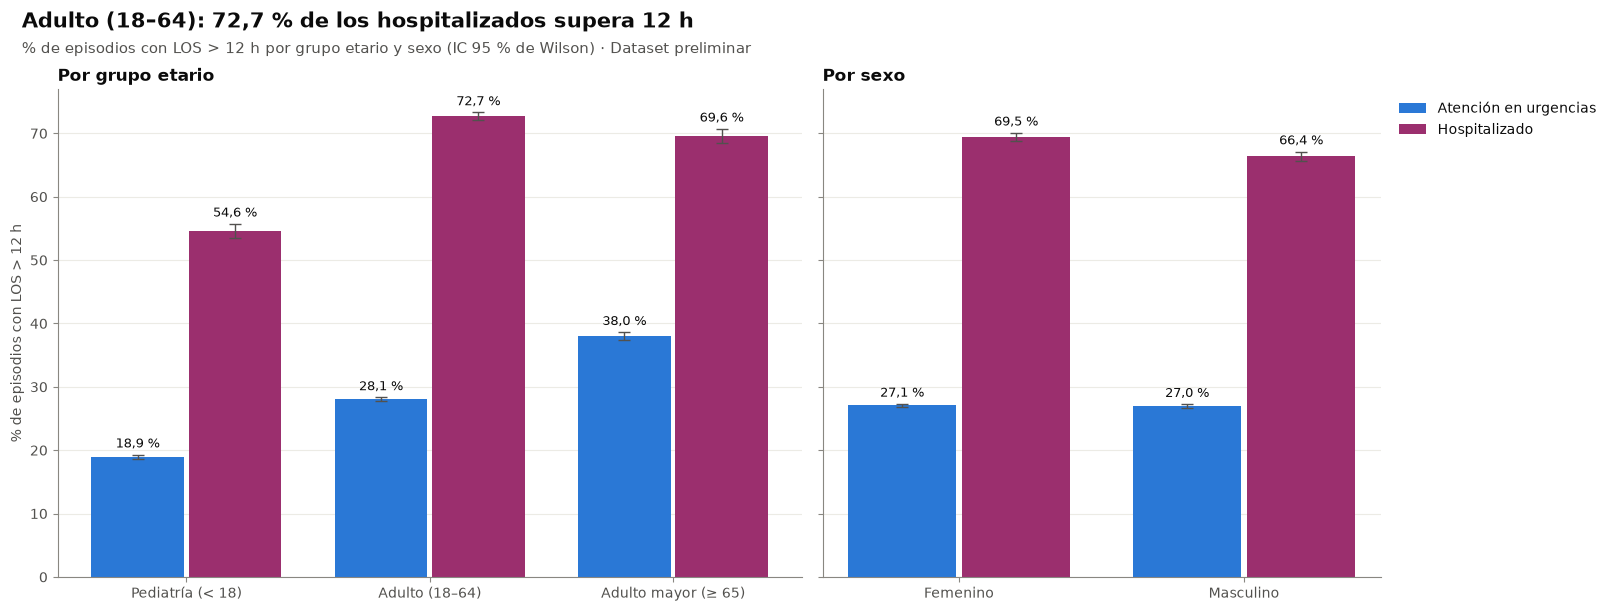

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [4, 3]}, sharey=True)
pct_edad_g3 = {}
for ax, (variable, categorias_posibles, nombres) in zip(ejes, [
    ('grupo_etario', ORDEN_EDAD, estilo.NOMBRE_GRUPO_ETARIO),
    ('sexo', ['femenino', 'masculino'], estilo.NOMBRE_SEXO),
]):
    tabla = tabla_los(tiempos, [variable, 'grupo'], umbrales=[UMBRAL])
    valido = puntos_validos(tabla, f'n_{SUFIJO}')
    categorias = [c for c in categorias_posibles if c in tabla.index.get_level_values(variable)]
    x = np.arange(len(categorias))
    for j, grupo in enumerate(config.GRUPOS_TIEMPOS):
        if grupo not in tabla.index.get_level_values('grupo'):
            continue
        parte = tabla.xs(grupo, level='grupo').reindex(categorias)
        validas = valido.xs(grupo, level='grupo').reindex(categorias, fill_value=False)
        barras_con_ic(ax, x, parte, f'pct_{SUFIJO}', f'ic_inf_{SUFIJO}', f'ic_sup_{SUFIJO}', validas, 0.38,
                      (j - 0.5) * 0.4, color=COLORES_GRUPO[grupo], label=ETIQUETAS_CORTAS_GRUPO[grupo])
        if grupo == G3 and variable == 'grupo_etario':
            pct_edad_g3 = parte[f'pct_{SUFIJO}'].where(validas).dropna().to_dict()
    ax.set_xticks(x, [nombres.get(c, c) for c in categorias])
    ax.set_title('Por grupo etario' if variable == 'grupo_etario' else 'Por sexo')
ejes[0].set_ylabel(f'% de episodios con LOS > {UMBRAL} h')
leyenda_fuera(ejes[1])
if pct_edad_g3:
    mayor = max(pct_edad_g3, key=pct_edad_g3.get)
    titulo = f'{estilo.NOMBRE_GRUPO_ETARIO[mayor]}: {fmt_pct(pct_edad_g3[mayor])} de los hospitalizados supera 12 h'
else:
    titulo = f'Episodios que superan {UMBRAL} h por edad y sexo'
titulo_figura(fig, titulo, f'% de episodios con LOS > {UMBRAL} h por grupo etario y sexo (IC 95 % de Wilson)')
guardar_figura(fig, f'04_mas_12h_edad_sexo_{DATASET}')
plt.show()

## 7. Hora de llegada × día de la semana

% de episodios del grupo 3 con LOS > 12 h y mediana del LOS del grupo 2. Las celdas con menos de 10 episodios quedan en blanco.

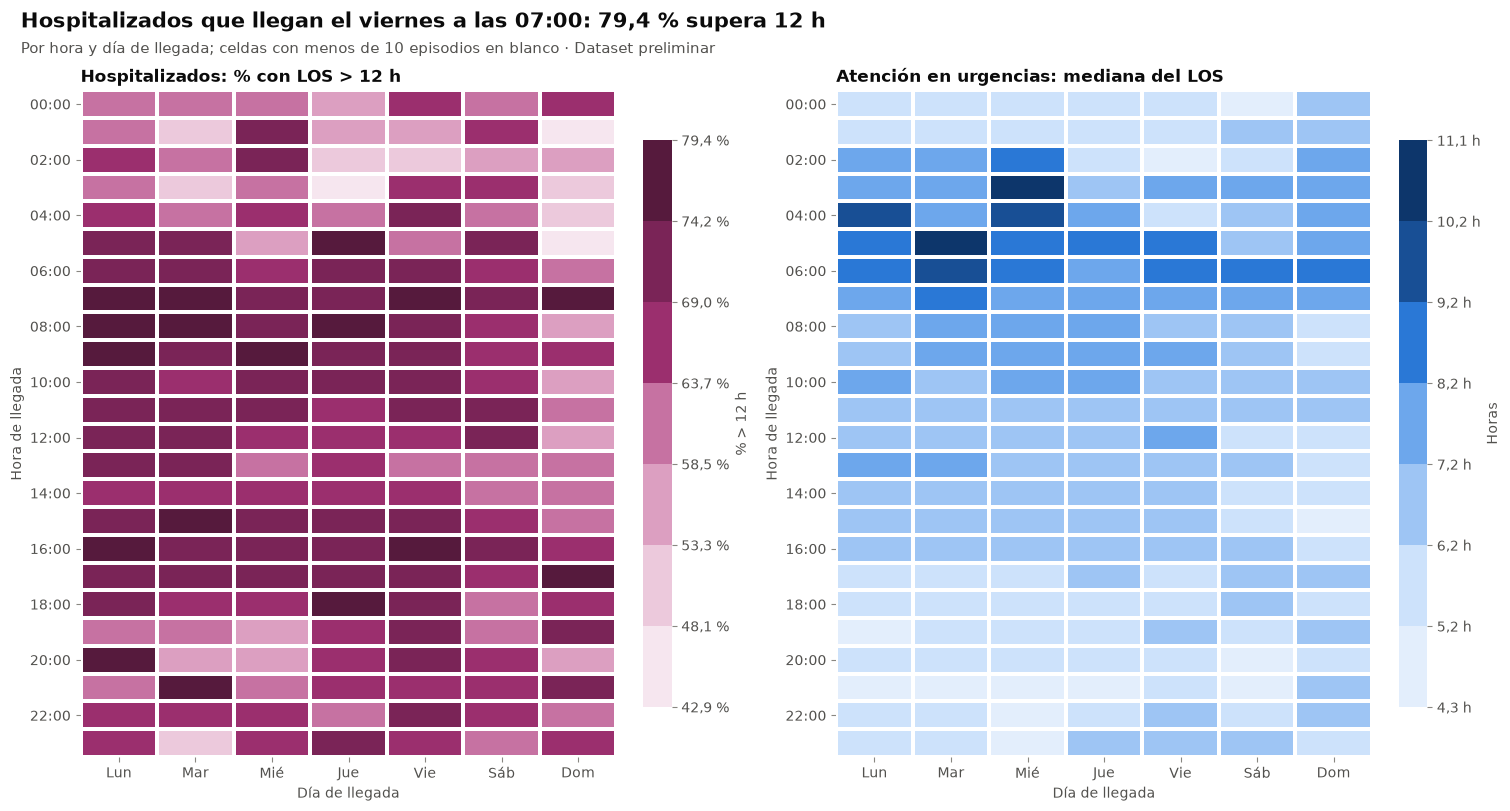

In [12]:
def matriz_hora_dia(datos, columna, estadistico):
    agrupado = datos.groupby(['hora_llegada', 'dia_semana'])[columna]
    n = agrupado.size().unstack('dia_semana')
    valores = agrupado.agg(estadistico).unstack('dia_semana')
    return enmascarar_pequenos(valores, n)


g3 = tiempos[(tiempos['grupo'] == G3) & tiempos['los_h'].notna()].assign(
    supera_umbral=lambda d: 100.0 * (d['los_h'] > UMBRAL)
)
g2 = tiempos[(tiempos['grupo'] == G2) & tiempos['los_h'].notna()]
pct_g3 = matriz_hora_dia(g3, 'supera_umbral', 'mean')
mediana_g2 = matriz_hora_dia(g2, 'los_h', 'median')

fig, ejes = plt.subplots(1, 2, figsize=(15, 8))
heatmap_hora_dia(ejes[0], pct_g3, f'Hospitalizados: % con LOS > {UMBRAL} h', f'% > {UMBRAL} h', familia='ciruela',
                 formato=estilo.tick_pct)
heatmap_hora_dia(ejes[1], mediana_g2, 'Atención en urgencias: mediana del LOS', 'Horas', familia='azul',
                 formato=estilo.tick_horas)
pila = pct_g3.stack()
if not pila.empty:
    hora, dia = pila.idxmax()
    titulo = f'Hospitalizados que llegan el {estilo.DIAS_SEMANA_COMPLETOS[dia]} a las {hora:02d}:00: {fmt_pct(pila.max())} supera 12 h'
else:
    titulo = 'LOS por hora y día de llegada'
titulo_figura(fig, titulo, 'Por hora y día de llegada; celdas con menos de 10 episodios en blanco')
guardar_figura(fig, f'04_heatmap_hora_dia_{DATASET}')
plt.show()

## 8. Tendencia mensual

Mediana del LOS y % > 12 h del grupo 3 (con IC de Wilson), y episodios por grupo.

In [13]:
mensual_g3 = tabla_los(tiempos[tiempos['grupo'] == G3], ['mes'], umbrales=[UMBRAL])
mensual_grupos = poblacion.groupby(['mes', 'grupo']).size().unstack('grupo', fill_value=0).reindex(
    columns=list(config.GRUPOS), fill_value=0)
mostrar_tabla(tabla_segura(mensual_g3))
mostrar_tabla(suprimir_pequenos(mensual_grupos, list(mensual_grupos.columns)))

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h
mes,,,,,,,,,
2023-01-01,978,"22,15","9,84","35,75","59,87",683,"69,8","66,9","72,6"
2023-02-01,855,"23,89","10,44","39,15","75,14",624,"73,0","69,9","75,8"
2023-03-01,990,"23,47","9,03","40,15","70,81",684,"69,1","66,1","71,9"
2023-04-01,1.001,"24,02","10,42","34,73","59,07",707,"70,6","67,7","73,4"
2023-05-01,995,"25,49","10,44","38,47","78,70",713,"71,7","68,8","74,4"
2023-06-01,964,"24,99","8,88","42,96","79,46",671,"69,6","66,6","72,4"
2023-07-01,978,"25,22","10,01","39,11","62,17",694,"71,0","68,0","73,7"
2023-08-01,997,"25,96","9,58","41,20","73,25",700,"70,2","67,3","73,0"
2023-09-01,896,"23,87","9,05","39,49","71,28",618,"69,0","65,9","71,9"


grupo,1_contacto_breve,2_atencion_urgencias,3_hospitalizado
mes,,,
2023-01-01,6.853,4.826,978
2023-02-01,6.114,4.506,855
2023-03-01,7.161,5.501,990
2023-04-01,6.994,4.864,1.001
2023-05-01,8.350,5.332,995
2023-06-01,7.117,5.174,964
2023-07-01,6.995,5.231,978
2023-08-01,6.852,5.244,997
2023-09-01,6.130,5.045,896


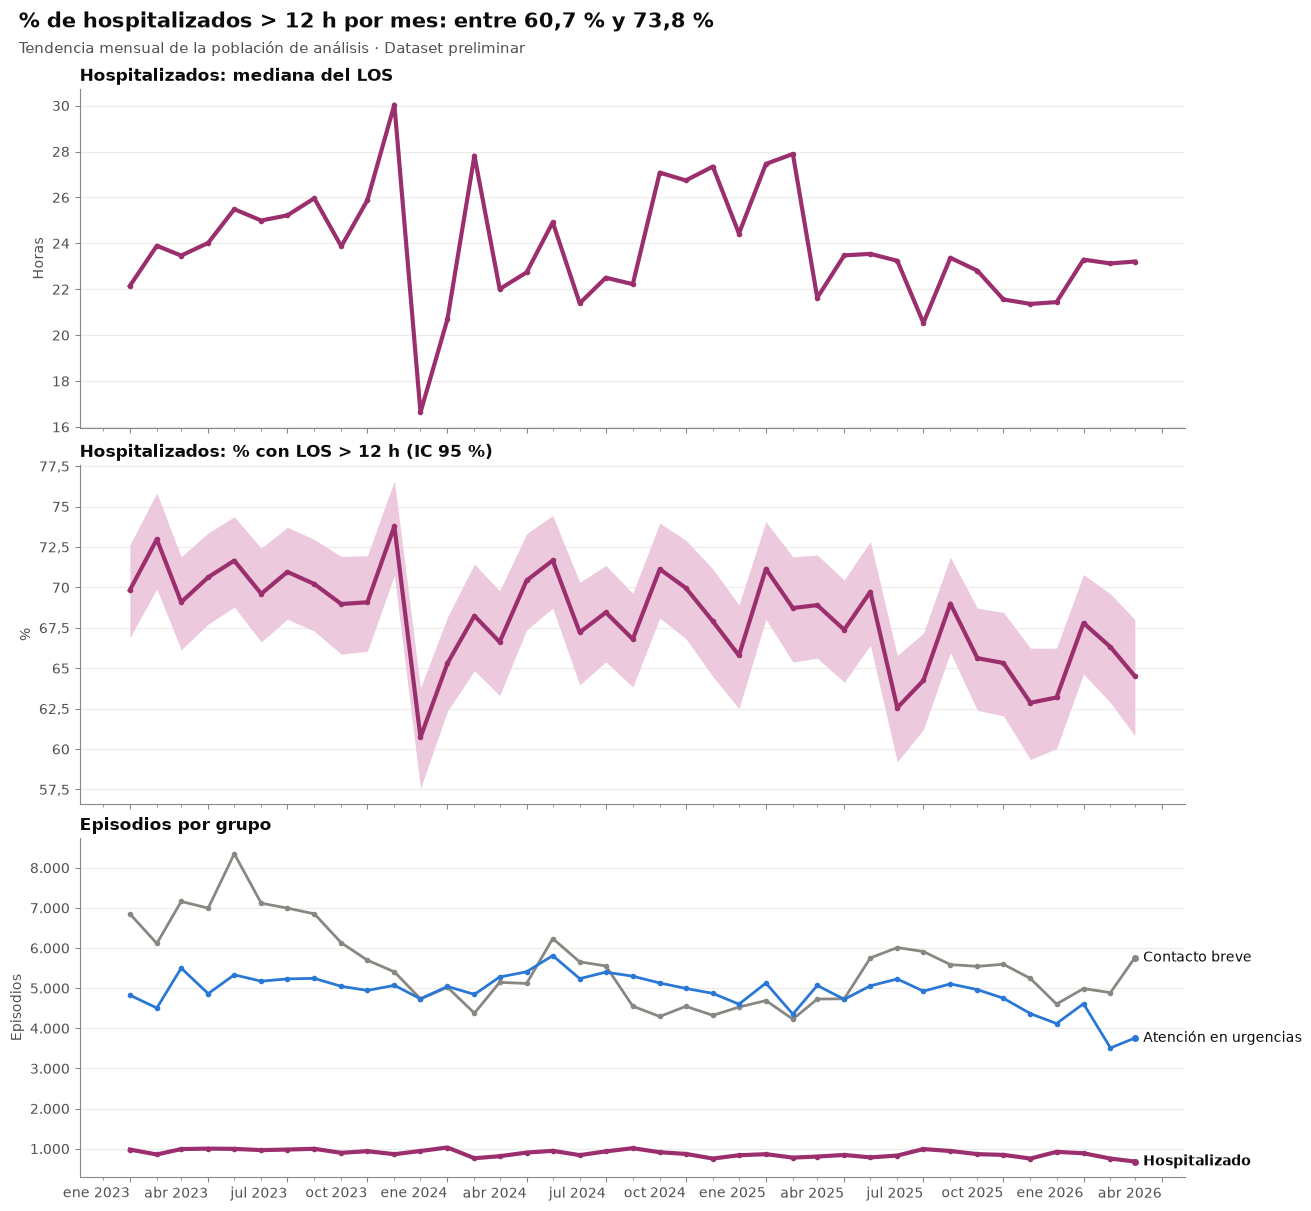

In [14]:
valido = puntos_validos(mensual_g3, f'n_{SUFIJO}')
fig, ejes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)

ejes[0].plot(mensual_g3.index, mensual_g3['mediana_h'].where(mensual_g3['n'] >= config.MIN_CELDA),
             marker='o', markersize=3, color=COLORES_GRUPO[G3], linewidth=ancho_linea(G3))
ejes[0].set_ylabel('Horas')
ejes[0].set_title('Hospitalizados: mediana del LOS')

pct_mes = mensual_g3[f'pct_{SUFIJO}'].where(valido)
ejes[1].plot(mensual_g3.index, pct_mes, marker='o', markersize=3, color=COLORES_GRUPO[G3], linewidth=ancho_linea(G3))
ejes[1].fill_between(mensual_g3.index, mensual_g3[f'ic_inf_{SUFIJO}'].where(valido),
                     mensual_g3[f'ic_sup_{SUFIJO}'].where(valido), color=estilo.RAMPA_CIRUELA[1], linewidth=0)
ejes[1].set_ylabel('%')
ejes[1].set_title(f'Hospitalizados: % con LOS > {UMBRAL} h (IC 95 %)')

for grupo in config.GRUPOS:
    valores = enmascarar_pequenos(mensual_grupos[grupo], mensual_grupos[grupo])
    ejes[2].plot(valores.index, valores, marker='o', markersize=3, color=COLORES_GRUPO[grupo], linewidth=ancho_linea(grupo))
    etiquetas_directas(ejes[2], valores.index, {ETIQUETAS_CORTAS_GRUPO[grupo]: (valores, COLORES_GRUPO[grupo])},
                       negrita=[ETIQUETAS_CORTAS_GRUPO[G3]])
ejes[2].set_ylabel('Episodios')
ejes[2].set_title('Episodios por grupo')
titulo_figura(fig, f'% de hospitalizados > 12 h por mes: entre {fmt_pct(pct_mes.min())} y {fmt_pct(pct_mes.max())}',
                'Tendencia mensual de la población de análisis')
guardar_figura(fig, f'04_tendencia_mensual_{DATASET}')
plt.show()

## 9. % > 12 h del grupo 3 según hospitalización previa en 30 días

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_4h,pct_mas_4h,ic_inf_mas_4h,ic_sup_mas_4h,n_mas_6h,pct_mas_6h,ic_inf_mas_6h,ic_sup_mas_6h,n_mas_8h,pct_mas_8h,ic_inf_mas_8h,ic_sup_mas_8h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h,n_mas_24h,pct_mas_24h,ic_inf_mas_24h,ic_sup_mas_24h,n_mas_72h,pct_mas_72h,ic_inf_mas_72h,ic_sup_mas_72h
hosp_previa_30d,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
False,33.872,"23,91","8,76",43,"78,34",29.690,"87,7","87,3","88,0",27.864,"82,3","81,8","82,7",26.030,"76,8","76,4","77,3",23.085,"68,2","67,7","68,7",16.895,"49,9","49,4","50,4",4.029,"11,9","11,6","12,2"
True,661,"26,14","8,69","52,47","96,89",579,"87,6","84,9","89,9",543,"82,2","79,0","84,9",506,"76,5","73,2","79,6",441,"66,7","63,0","70,2",350,"53,0","49,1","56,7",108,"16,3","13,7","19,4"


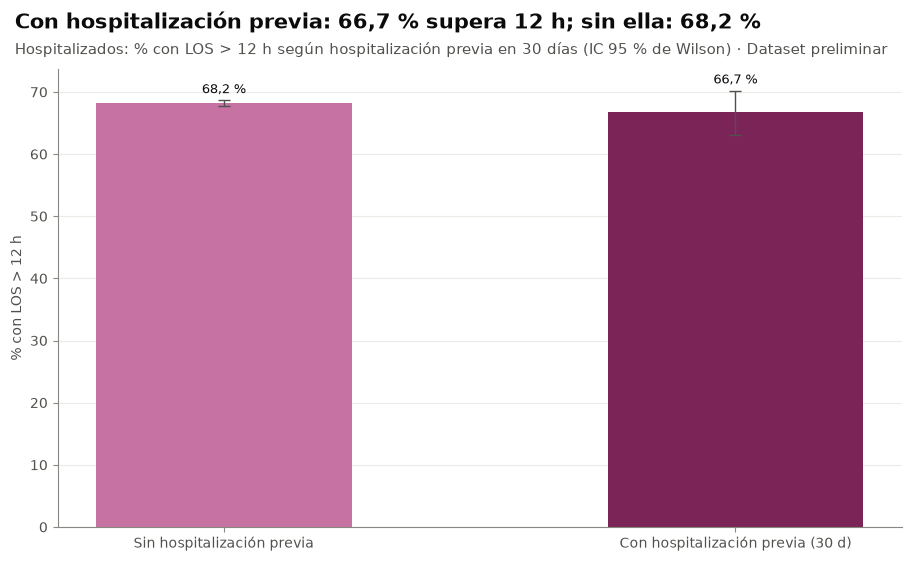

In [15]:
por_hosp_previa = tabla_los(tiempos[tiempos['grupo'] == G3], ['hosp_previa_30d'])
mostrar_tabla(tabla_segura(por_hosp_previa))
tabla = por_hosp_previa.reindex([False, True])
valido = puntos_validos(tabla, f'n_{SUFIJO}')
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(2)
barras_con_ic(ax, x, tabla, f'pct_{SUFIJO}', f'ic_inf_{SUFIJO}', f'ic_sup_{SUFIJO}', valido, 0.5, 0,
              color=[estilo.RAMPA_CIRUELA[3], estilo.RAMPA_CIRUELA[5]])
ax.set_xticks(x, ['Sin hospitalización previa', 'Con hospitalización previa (30 d)'])
ax.set_ylabel(f'% con LOS > {UMBRAL} h')
pct = tabla[f'pct_{SUFIJO}'].where(valido)
titulo_figura(fig, f'Con hospitalización previa: {fmt_pct(pct.iloc[1])} supera 12 h; sin ella: {fmt_pct(pct.iloc[0])}',
                f'Hospitalizados: % con LOS > {UMBRAL} h según hospitalización previa en 30 días (IC 95 % de Wilson)')
guardar_figura(fig, f'04_mas_12h_hosp_previa_{DATASET}')
plt.show()

## 10. Contactos breves (grupo 1)

Volumen por hora y por mes, y % con `nota_consulta_urg`. No se analizan tiempos.

In [16]:
breves = poblacion[poblacion['grupo'] == G1]
por_hora = pd.DataFrame({
    'n_contactos_breves': breves.groupby('hora_llegada').size(),
    'n_episodios': poblacion.groupby('hora_llegada').size(),
}).fillna(0).astype('int64').rename_axis('hora_llegada')
por_hora['pct_contactos_breves'] = 100 * por_hora['n_contactos_breves'] / por_hora['n_episodios']
mostrar_tabla(tabla_segura(por_hora))
por_mes = pd.DataFrame({
    'n_contactos_breves': breves.groupby('mes').size(),
    'n_episodios': poblacion.groupby('mes').size(),
}).fillna(0).astype('int64').rename_axis('mes')
por_mes['pct_contactos_breves'] = 100 * por_mes['n_contactos_breves'] / por_mes['n_episodios']
mostrar_tabla(tabla_segura(por_mes))
nota_breves = tabla_proporciones(breves.assign(sin_etapas_txt=breves['sin_etapas'].map({True: 'sin etapas', False: 'con etapas < 5 min'})),
                                 ['sin_etapas_txt'], 'nota_consulta_urg')
mostrar_tabla(tabla_segura(nota_breves))
nota_mes = tabla_proporciones(breves, ['mes'], 'nota_consulta_urg')

,n_contactos_breves,n_episodios,pct_contactos_breves
hora_llegada,,,
0,3.199,6.884,"46,5"
1,2.515,5.190,"48,5"
2,1.952,4.289,"45,5"
3,1.871,3.975,"47,1"
4,1.753,3.871,"45,3"
5,3.299,6.582,"50,1"
6,7.218,13.664,"52,8"
7,13.042,24.899,"52,4"
8,16.712,31.476,"53,1"


,n_contactos_breves,n_episodios,pct_contactos_breves
mes,,,
2023-01-01,6.853,12.657,"54,1"
2023-02-01,6.114,11.475,"53,3"
2023-03-01,7.161,13.652,"52,5"
2023-04-01,6.994,12.859,"54,4"
2023-05-01,8.350,14.677,"56,9"
2023-06-01,7.117,13.255,"53,7"
2023-07-01,6.995,13.204,"53,0"
2023-08-01,6.852,13.093,"52,3"
2023-09-01,6.130,12.071,"50,8"


,n,n_eventos,pct_eventos,ic_inf_eventos,ic_sup_eventos
sin_etapas_txt,,,,,
con etapas < 5 min,189.317,69.188,"36,5","36,3","36,8"
sin etapas,26.702,1.606,"6,0","5,7","6,3"


/var/home/luencaro/Programing/College/2026-30/Data Challenge HUN/patient-flow-HUN/src/graficos.py:654: UserWarning: Figura 04_contactos_breves_preliminar: 26 pares de textos superpuestos, por ejemplo «ene 2023» y «abr 2023»; «abr 2023» y «jul 2023»; «jul 2023» y «oct 2023»; «oct 2023» y «ene 2024»; «ene 2024» y «abr 2024».
  revisar_solapes(fig, nombre)


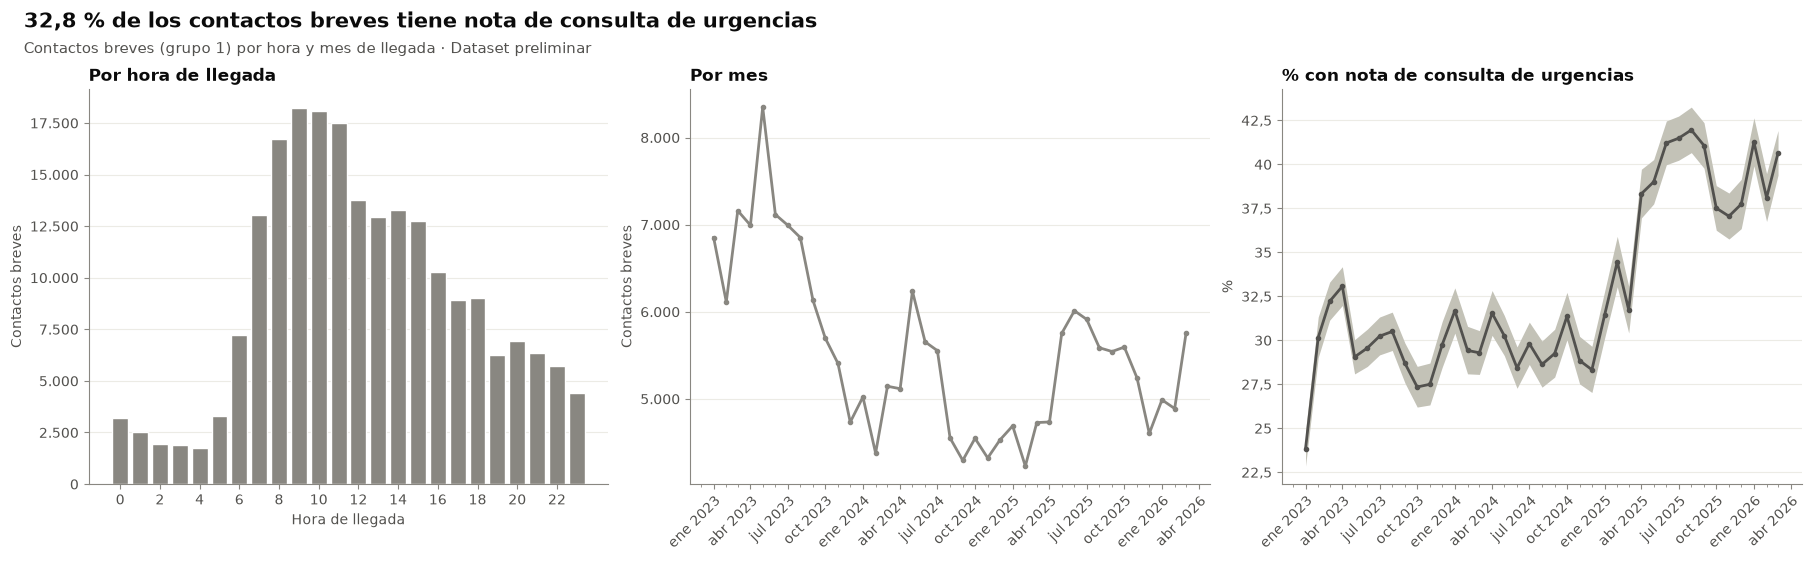

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5))
n_hora = enmascarar_pequenos(por_hora['n_contactos_breves'], por_hora['n_contactos_breves'])
ejes[0].bar(n_hora.index, n_hora, color=estilo.GRIS_CONTEXTO, edgecolor='white', linewidth=1)
ejes[0].set_xticks(range(0, 24, 2))
ejes[0].set_xlabel('Hora de llegada')
ejes[0].set_ylabel('Contactos breves')
ejes[0].set_title('Por hora de llegada')

n_mes = enmascarar_pequenos(por_mes['n_contactos_breves'], por_mes['n_contactos_breves'])
ejes[1].plot(n_mes.index, n_mes, marker='o', markersize=3, color=estilo.GRIS_CONTEXTO)
ejes[1].set_ylabel('Contactos breves')
ejes[1].set_title('Por mes')

valido = puntos_validos(nota_mes)
ejes[2].plot(nota_mes.index, nota_mes['pct_eventos'].where(valido), marker='o', markersize=3, color=OSCURO)
ejes[2].fill_between(nota_mes.index, nota_mes['ic_inf_eventos'].where(valido), nota_mes['ic_sup_eventos'].where(valido),
                     color=CLARO, linewidth=0)
ejes[2].set_ylabel('%')
ejes[2].set_title('% con nota de consulta de urgencias')
titulo_figura(fig, f"{fmt_pct(100 * breves['nota_consulta_urg'].mean())} de los contactos breves tiene nota de consulta de urgencias",
                'Contactos breves (grupo 1) por hora y mes de llegada')
guardar_figura(fig, f'04_contactos_breves_{DATASET}')
plt.show()

## 11. Reconsultas
### 11.1 Tasas por grupo

Reconsulta a 72 h y a 7 días, con y sin censura, con IC de Wilson al 95 %. Referencia de DBeaver (reglas anteriores): 5,4 % a 72 h en total.

In [18]:
partes = []
datos = poblacion.assign(total='todos')
for ventana in config.VENTANAS_RECONSULTA:
    for censura, columna in [('con_censura', f'reconsulta_{ventana}'), ('sin_censura', f'reconsulta_{ventana}_sin_censura')]:
        for por in ['grupo', 'total']:
            tabla = tabla_proporciones(datos, [por], columna).rename_axis('grupo')
            partes.append(tabla.assign(ventana=ventana, censura=censura).set_index(['ventana', 'censura'], append=True))

tasas = pd.concat(partes).reorder_levels(['ventana', 'censura', 'grupo']).sort_index()
mostrar_tabla(tabla_segura(tasas))

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
ventana censura     grupo                                                                            
72h     con_censura 1_contacto_breve      216.019    11.918         5,5            5,4            5,6
                    2_atencion_urgencias  192.046    12.318         6,4            6,3            6,5
                    3_hospitalizado        34.531     1.035         3,0            2,8            3,2
                    todos                 442.596    25.271         5,7            5,6            5,8
        sin_censura 1_contacto_breve      216.019    11.918         5,5            5,4            5,6
                    2_atencion_urgencias  192.046    12.318         6,4            6,3            6,5
                    3_hospitalizado        34.533     1.035         3,0            2,8            3,2
                    todos                 442.598    25.271         5,7            5,6            5,8
7d      con_censura 1_contacto_breve      216.019    17.584         8,1            8,0            8,3
                    2_atencion_urgencias  192.046    19.015         9,9            9,8           10,0
                    3_hospitalizado        34.531     2.210         6,4            6,2            6,7
                    todos                 442.596    38.809         8,8            8,7            8,8
        sin_censura 1_contacto_breve      216.019    17.584         8,1            8,0            8,3
                    2_atencion_urgencias  192.046    19.015         9,9            9,8           10,0
                    3_hospitalizado        34.533     2.210         6,4            6,2            6,7
                    todos                 442.598    38.809         8,8            8,7            8,8

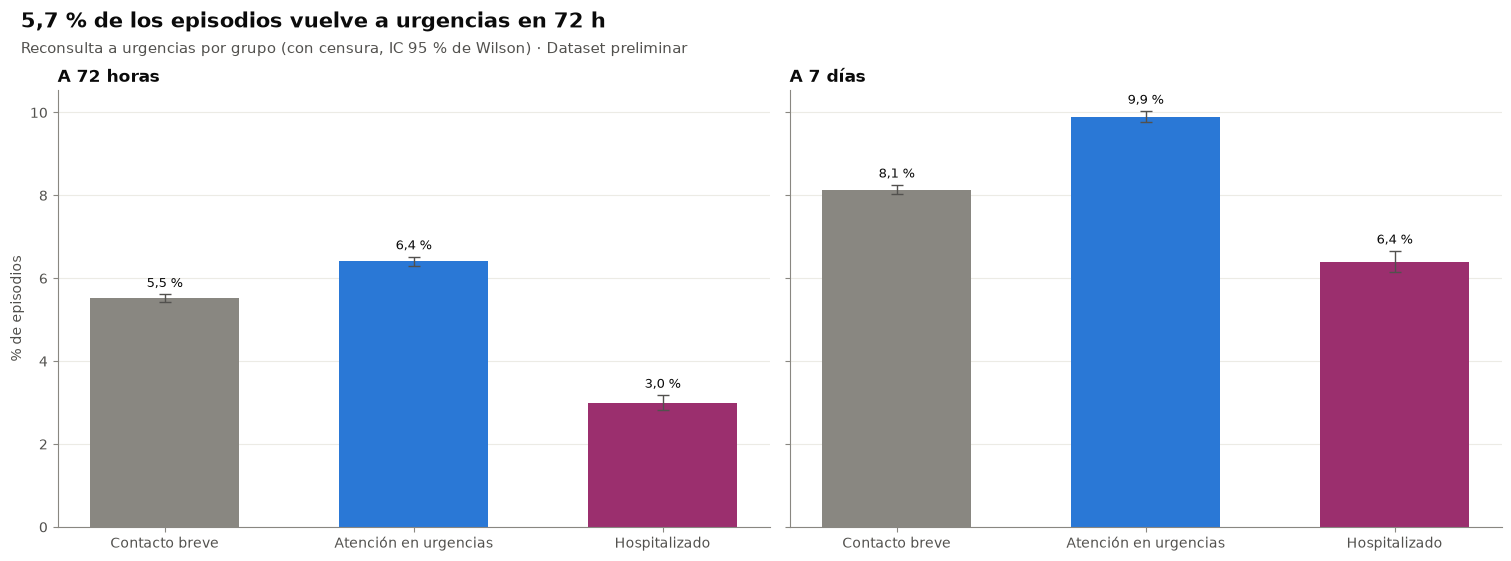

In [19]:
con_censura = tasas.xs('con_censura', level='censura')
grupos = list(config.GRUPOS)
x = np.arange(len(grupos))
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, ventana, titulo in zip(ejes, config.VENTANAS_RECONSULTA, ['A 72 horas', 'A 7 días']):
    tabla = con_censura.xs(ventana, level='ventana').reindex(grupos)
    barras_con_ic(ax, x, tabla, 'pct_eventos', 'ic_inf_eventos', 'ic_sup_eventos', puntos_validos(tabla), 0.6, 0,
                  color=[COLORES_GRUPO[g] for g in grupos])
    ax.set_xticks(x, [ETIQUETAS_CORTAS_GRUPO[g] for g in grupos])
    ax.set_title(titulo)
ejes[0].set_ylabel('% de episodios')
total_72h = valor_seguro(con_censura.xs('72h', level='ventana'), 'todos', 'pct_eventos', 'n_eventos')
titulo_figura(fig, f'{fmt_pct(total_72h)} de los episodios vuelve a urgencias en 72 h',
                'Reconsulta a urgencias por grupo (con censura, IC 95 % de Wilson)')
guardar_figura(fig, f'04_reconsulta_por_grupo_{DATASET}')
plt.show()

### 11.2 Reconsulta a 72 h por perfil del episodio índice

Con censura. Por grupo etario, hora de llegada y tramo de LOS (solo grupos 2 y 3, que tienen tiempos).

In [20]:
columna_72h = 'reconsulta_72h'
for variable in ['grupo_etario', 'hora_llegada', 'tramo_los']:
    datos = tiempos if variable == 'tramo_los' else poblacion
    mostrar_tabla(tabla_segura(tabla_proporciones(datos, ['grupo', variable], columna_72h)))

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
grupo                grupo_etario                                                             
1_contacto_breve     adulto        134.970     6.924         5,1            5,0            5,2
                     adulto_mayor   17.144       783         4,6            4,3            4,9
                     pediatria      63.905     4.211         6,6            6,4            6,8
2_atencion_urgencias adulto        118.359     7.721         6,5            6,4            6,7
                     adulto_mayor   24.621     1.206         4,9            4,6            5,2
                     pediatria      49.066     3.391         6,9            6,7            7,1
3_hospitalizado      adulto         20.089       626         3,1            2,9            3,4
                     adulto_mayor    6.881       187         2,7            2,4            3,1
                     pediatria       7.561       222         2,9            2,6            3,3

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
grupo            hora_llegada                                                           
1_contacto_breve 0             3.199       357        11,2           10,1           12,3
                 1             2.515       377        15,0           13,7           16,4
                 2             1.952       294        15,1           13,5           16,7
                 3             1.871       251        13,4           11,9           15,0
                 4             1.753       244        13,9           12,4           15,6
...                              ...       ...         ...            ...            ...
3_hospitalizado  19            1.217        22         1,8            1,2            2,7
                 20            1.283        44         3,4            2,6            4,6
                 21            1.197        26         2,2            1,5            3,2
                 22            1.080        38         3,5            2,6            4,8
                 23              905        23         2,5            1,7            3,8

[72 rows x 5 columns]

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
grupo                tramo_los                                                               
2_atencion_urgencias menos de 4 h  73.382     5.003         6,8            6,6            7,0
                     4 a 12 h      66.774     4.646         7,0            6,8            7,2
                     12 a 24 h     28.338     1.839         6,5            6,2            6,8
                     24 h o más    23.552       830         3,5            3,3            3,8
3_hospitalizado      menos de 4 h   4.263       118         2,8            2,3            3,3
                     4 a 12 h       6.744       162         2,4            2,1            2,8
                     12 a 24 h      6.281       215         3,4            3,0            3,9
                     24 h o más    17.243       540         3,1            2,9            3,4

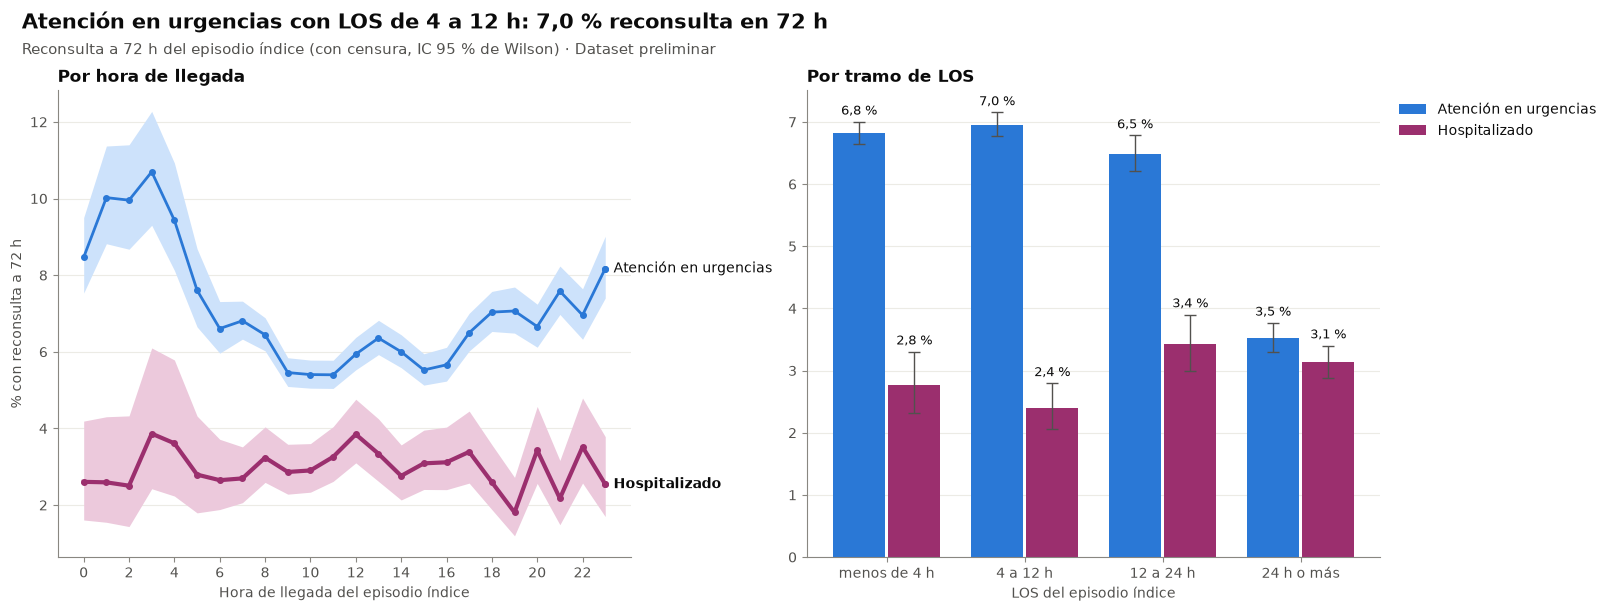

In [21]:
por_hora_r = tabla_proporciones(tiempos, ['grupo', 'hora_llegada'], columna_72h)
por_tramo = tabla_proporciones(tiempos, ['grupo', 'tramo_los'], columna_72h)

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for grupo in config.GRUPOS_TIEMPOS:
    tabla = por_hora_r.xs(grupo, level='grupo')
    valido = puntos_validos(tabla)
    pct = tabla['pct_eventos'].where(valido)
    color = COLORES_GRUPO[grupo]
    ejes[0].plot(tabla.index, pct, marker='o', markersize=4, color=color, linewidth=ancho_linea(grupo))
    ejes[0].fill_between(tabla.index, tabla['ic_inf_eventos'].where(valido), tabla['ic_sup_eventos'].where(valido),
                         color=estilo.tonos(estilo.FAMILIA_ROL[grupo], 2)[0], linewidth=0)
    etiquetas_directas(ejes[0], tabla.index, {ETIQUETAS_CORTAS_GRUPO[grupo]: (pct, color)},
                       negrita=[ETIQUETAS_CORTAS_GRUPO[G3]])
ejes[0].set_xticks(range(0, 24, 2))
ejes[0].set_xlabel('Hora de llegada del episodio índice')
ejes[0].set_ylabel('% con reconsulta a 72 h')
ejes[0].set_title('Por hora de llegada')

tramos = list(episodios['tramo_los'].cat.categories)
x = np.arange(len(tramos))
pct_tramo_g2 = {}
for j, grupo in enumerate(config.GRUPOS_TIEMPOS):
    tabla = por_tramo.xs(grupo, level='grupo').reindex(tramos)
    barras_con_ic(ejes[1], x, tabla, 'pct_eventos', 'ic_inf_eventos', 'ic_sup_eventos', puntos_validos(tabla),
                  0.38, (j - 0.5) * 0.4, color=COLORES_GRUPO[grupo], label=ETIQUETAS_CORTAS_GRUPO[grupo])
    if grupo == G2:
        pct_tramo_g2 = tabla['pct_eventos'].where(puntos_validos(tabla)).dropna().to_dict()
leyenda_fuera(ejes[1])
ejes[1].set_xticks(x, tramos)
ejes[1].set_xlabel('LOS del episodio índice')
ejes[1].set_title('Por tramo de LOS')
if pct_tramo_g2:
    mayor = max(pct_tramo_g2, key=pct_tramo_g2.get)
    titulo = f'Atención en urgencias con LOS de {mayor}: {fmt_pct(pct_tramo_g2[mayor])} reconsulta en 72 h'
else:
    titulo = 'Reconsulta a 72 h por hora de llegada y tramo de LOS'
titulo_figura(fig, titulo, 'Reconsulta a 72 h del episodio índice (con censura, IC 95 % de Wilson)')
guardar_figura(fig, f'04_reconsulta_hora_tramo_los_{DATASET}')
plt.show()

### 11.3 Tiempo hasta el siguiente episodio

Distribución, en bloques de 6 horas, del tiempo entre el fin del episodio y la llegada del siguiente durante los primeros 7 días (solo episodios observables a 7 días). Por construcción no hay valores menores al umbral de fusión (60 min).

,n_episodios
horas_hasta_siguiente_tramo,
"(0.0, 24.0]",10.634
"(24.0, 48.0]",8.552
"(48.0, 72.0]",6.085
"(72.0, 96.0]",4.211
"(96.0, 120.0]",3.469
"(120.0, 144.0]",2.929
"(144.0, 168.0]",2.929


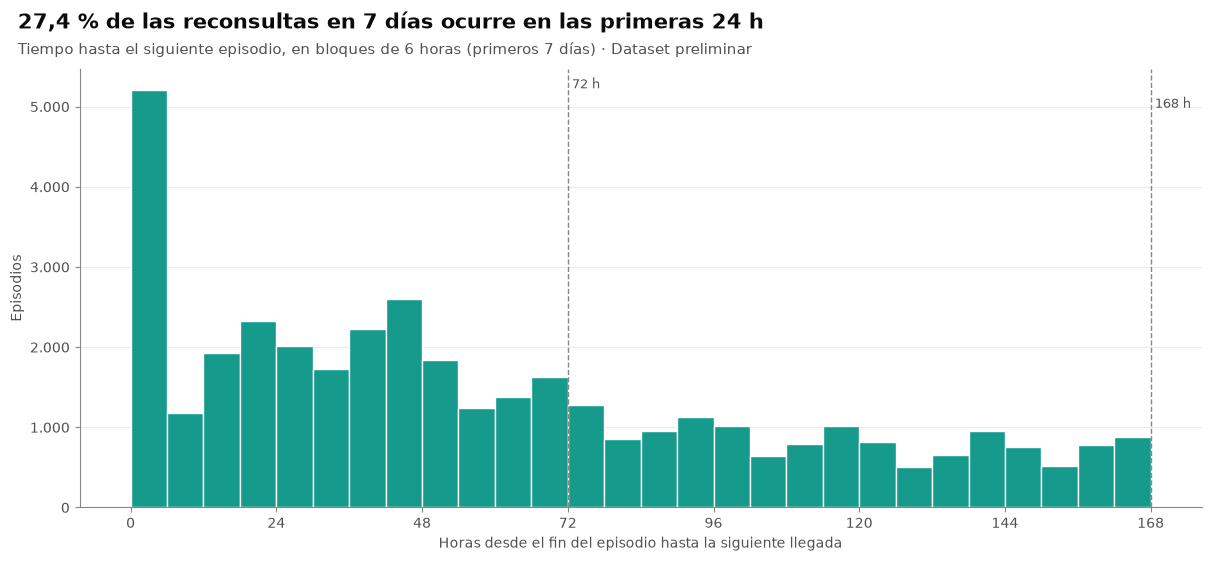

In [22]:
limite_7d_h = config.VENTANAS_RECONSULTA['7d'] / pd.Timedelta(hours=1)
observables = poblacion[poblacion['reconsulta_7d'].notna()]
horas = observables.loc[observables['horas_hasta_siguiente'] <= limite_7d_h, 'horas_hasta_siguiente']

por_dia = (
    pd.cut(horas, bins=np.arange(0, limite_7d_h + 1, 24), right=True)
    .value_counts().sort_index().rename('n_episodios').rename_axis('horas_hasta_siguiente_tramo').to_frame()
)
por_dia.index = por_dia.index.astype(str)
mostrar_tabla(suprimir_pequenos(por_dia, ['n_episodios']))
bordes = np.arange(0, limite_7d_h + 1, 6)
conteos, _ = np.histogram(horas, bins=bordes)
conteos_graf = np.where(conteos >= config.MIN_CELDA, conteos, np.nan)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(bordes[:-1], conteos_graf, width=6, align='edge', color=estilo.VERDE, edgecolor='white', linewidth=1)
marcar_umbrales(ax, [72, 168])
ax.set_xticks(range(0, int(limite_7d_h) + 1, 24))
ax.set_xlabel('Horas desde el fin del episodio hasta la siguiente llegada')
ax.set_ylabel('Episodios')
titulo_figura(fig, f'{fmt_pct(100 * (horas <= 24).mean())} de las reconsultas en 7 días ocurre en las primeras 24 h',
                'Tiempo hasta el siguiente episodio, en bloques de 6 horas (primeros 7 días)')
guardar_figura(fig, f'04_tiempo_hasta_siguiente_{DATASET}')
plt.show()

### 11.4 Episodios por paciente al año

Tabla de frecuencias agregada (1, 2, 3, 4–5, 6–9, 10 o más episodios por paciente y año). 2026 es un año parcial (hasta marzo).

In [23]:
por_paciente_anio = poblacion.groupby([poblacion['person_id'], poblacion['llegada'].dt.year.rename('anio')]).size()
conteo_anual = pd.DataFrame({
    'anio': por_paciente_anio.index.get_level_values('anio'),
    'categoria': pd.cut(
        por_paciente_anio.to_numpy(), bins=[0, 1, 2, 3, 5, 9, np.inf], labels=['1', '2', '3', '4-5', '6-9', '10+']
    ),
    'episodios': por_paciente_anio.to_numpy(),
})
del por_paciente_anio  # se descarta el nivel con identificadores

pacientes = conteo_anual.groupby(['categoria', 'anio'], observed=False).size().unstack('anio', fill_value=0)
episodios_cat = conteo_anual.groupby(['categoria', 'anio'], observed=False)['episodios'].sum().unstack('anio', fill_value=0)
frecuentes = pd.concat(
    [
        pacientes.add_prefix('n_pacientes_'),
        (100 * pacientes / pacientes.sum()).add_prefix('pct_pacientes_'),
        episodios_cat.add_prefix('n_episodios_'),
        (100 * episodios_cat / episodios_cat.sum()).add_prefix('pct_episodios_'),
    ],
    axis=1,
).rename_axis('episodios_por_paciente_anio')
frecuentes.columns.name = None
mostrar_tabla(tabla_segura(frecuentes, decimales=1))

,n_pacientes_2023,n_pacientes_2024,n_pacientes_2025,n_pacientes_2026,pct_pacientes_2023,pct_pacientes_2024,pct_pacientes_2025,pct_pacientes_2026,n_episodios_2023,n_episodios_2024,n_episodios_2025,n_episodios_2026,pct_episodios_2023,pct_episodios_2024,pct_episodios_2025,pct_episodios_2026
episodios_por_paciente_anio,,,,,,,,,,,,,,,,
1,66.892,60.147,61.116,20.686,"68,7","69,7","70,8","84,3",66.892,60.147,61.116,20.686,"44,5","45,6","46,8","69,3"
2,18.781,16.298,15.582,2.950,"19,3","18,9","18,0","12,0",37.562,32.596,31.164,5.900,"25,0","24,7","23,9","19,8"
3,6.581,5.470,5.361,623,"6,8","6,3","6,2","2,5",19.743,16.410,16.083,1.869,"13,1","12,4","12,3","6,3"
4-5,3.828,3.258,3.161,246,"3,9","3,8","3,7","1,0",16.469,14.003,13.604,1.072,"11,0","10,6","10,4","3,6"
6-9,1.063,915,993,37,"1,1","1,1","1,1","0,2",7.187,6.241,6.730,252,"4,8","4,7","5,2","0,8"
10+,188,179,149,<10,"0,2","0,2","0,2",suprimido,2.417,2.470,1.929,56,"1,6","1,9","1,5","0,2"


# Parte C · Exportación
## 12. Exportación para el dashboard

Tablas agregadas y con supresión para el dashboard, en `data/processed/`. Solo se escriben cuando `DATASET == 'final'`.

In [24]:
EXPORTAR = DATASET == 'final'
if not EXPORTAR:
    tabla_medidas({'dataset': DATASET, 'exportación': 'no se escriben archivos (solo con DATASET = "final")'},
                  'Exportación para el dashboard')

**Exportación para el dashboard**

,medida,valor
0,dataset,preliminar
1,exportación,"no se escriben archivos (solo con DATASET = ""final"")"


In [25]:
if EXPORTAR:
    dimensiones = ['total', 'grupo_etario', 'sexo', 'hora_llegada', 'dia_semana', 'mes', 'hosp_previa_30d']
    partes = []
    for dimension in dimensiones:
        if dimension == 'total':
            categoria = pd.Series('total', index=tiempos.index)
        elif dimension == 'dia_semana':
            categoria = tiempos['dia_semana'].map(dict(enumerate(DIAS_SEMANA)))
        elif dimension == 'mes':
            categoria = tiempos['mes'].dt.strftime('%Y-%m')
        else:
            categoria = tiempos[dimension].astype(str)
        tabla = tabla_los(tiempos.assign(categoria=categoria), ['grupo', 'categoria'])
        partes.append(tabla.assign(dimension=dimension).set_index('dimension', append=True))

    resumen_los = pd.concat(partes).reorder_levels(['dimension', 'grupo', 'categoria'])
    resumen_los_seguro = tabla_segura(resumen_los, decimales=3)

    config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
    resumen_los_seguro.reset_index().to_csv(config.DATA_PROCESSED / 'resumen_los.csv', index=False)
    tabla_medidas({'archivo': 'data/processed/resumen_los.csv', 'filas': len(resumen_los_seguro)}, 'Exportado')

In [26]:
if EXPORTAR:
    dimensiones = ['total', 'grupo_etario', 'sexo', 'hora_llegada', 'tramo_los', 'hosp_previa_30d']
    partes = []
    for ventana in config.VENTANAS_RECONSULTA:
        for censura, columna in [('con_censura', f'reconsulta_{ventana}'), ('sin_censura', f'reconsulta_{ventana}_sin_censura')]:
            for dimension in dimensiones:
                datos = tiempos if dimension == 'tramo_los' else poblacion
                if dimension == 'total':
                    categoria = pd.Series('total', index=datos.index)
                else:
                    categoria = datos[dimension].astype(str).where(datos[dimension].notna())
                tabla = tabla_proporciones(datos.assign(categoria=categoria), ['grupo', 'categoria'], columna)
                partes.append(
                    tabla.assign(ventana=ventana, censura=censura, dimension=dimension)
                    .set_index(['ventana', 'censura', 'dimension'], append=True)
                )

    resumen_reconsultas = pd.concat(partes).reorder_levels(['ventana', 'censura', 'dimension', 'grupo', 'categoria'])
    resumen_reconsultas_seguro = tabla_segura(resumen_reconsultas, decimales=3)
    resumen_reconsultas_seguro.reset_index().to_csv(config.DATA_PROCESSED / 'resumen_reconsultas.csv', index=False)
    tabla_medidas({'archivo': 'data/processed/resumen_reconsultas.csv', 'filas': len(resumen_reconsultas_seguro)}, 'Exportado')

In [27]:
if EXPORTAR:
    conteo_mes = poblacion.groupby(['mes', 'grupo']).size().rename('n').to_frame()
    conteo_mes['pct_del_mes'] = 100 * conteo_mes['n'] / conteo_mes.groupby(level='mes')['n'].transform('sum')
    los_mes = tabla_los(tiempos, ['mes', 'grupo'], umbrales=[UMBRAL])
    resumen_grupos_mes = conteo_mes.join(los_mes.drop(columns='n'))
    resumen_grupos_mes_seguro = tabla_segura(resumen_grupos_mes, decimales=3).reset_index()
    resumen_grupos_mes_seguro['mes'] = resumen_grupos_mes_seguro['mes'].dt.strftime('%Y-%m')
    resumen_grupos_mes_seguro.to_csv(config.DATA_PROCESSED / 'resumen_grupos_mes.csv', index=False)
    tabla_medidas({'archivo': 'data/processed/resumen_grupos_mes.csv', 'filas': len(resumen_grupos_mes_seguro)}, 'Exportado')